<a href="https://colab.research.google.com/github/Deyv0R/repo1/blob/main/%D0%9B%D0%A07_%D0%9A%D0%B8%D1%8F%D0%BD%D0%B8%D1%86%D1%8F_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [ ]:
# Варіант 1. Завантаження файлу в Google Colab
# from google.colab import files
# files.upload()
# df = pd.read_csv('data.csv')
# df.head()

In [2]:
import kagglehub
import os
path = kagglehub.dataset_download('unmoved/cure-the-princess')
df = pd.read_csv(os.path.join(path, 'data.csv'))
df.head()

100%|██████████| 49.2k/49.2k [00:00<00:00, 2.45MB/s]

Extracting files...


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [3]:
display(df.head())
print("Розмір датасету:", df.shape)
df.info()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


Розмір датасету: (2338, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [6]:
print("Кількість пропусків:\n", df.isnull().sum())
print("\nКількість дублікатів:", df.duplicated().sum())

Кількість пропусків:
 Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Кількість дублікатів: 0


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Phoenix Feather,2338.0,15.365697,8.669969,1.0,8.500,14.7,21.300,42.1
Unicorn Horn,2338.0,10.946749,7.225162,1.0,5.300,9.5,15.575,34.1
Dragon's Blood,2338.0,16.115654,8.372518,1.0,9.600,15.8,22.000,40.8
Mermaid Tears,2338.0,13.627973,7.545244,1.0,7.600,13.1,19.000,35.8
Fairy Dust,2338.0,15.069504,8.349340,1.0,8.625,14.5,20.700,40.4
Goblin Toes,2338.0,14.157271,7.831476,1.0,7.900,13.5,19.500,37.8
Witch's Brew,2338.0,12.328914,7.709753,1.0,6.325,11.2,16.900,37.3
Griffin Claw,2338.0,14.911206,8.132678,1.0,8.400,14.4,20.500,39.4
Troll Hair,2338.0,16.871685,9.579027,1.0,8.900,16.3,24.000,44.8
Kraken Ink,2338.0,14.890590,8.014197,1.0,8.800,14.4,20.400,39.5


**Висновок за первинним оглядом:**  
Датасет містить 2338 рядків і 14 стовпців. Пропущених значень та повних дублікатів у наборі даних не виявлено. Мінімальне значення для всіх магічних інгредієнтів становить 1.0, проте максимальні значення та стандартні відхилення відрізняються (наприклад, для Minotaur Horn максимум дорівнює 33.7 при $\text{std} \approx 7.05$, а для Troll Hair — 44.8 при $\text{std} \approx 9.58$), що вказує на потребу в стандартизації перед навчанням лінійних і метричних моделей.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [8]:
X = df.drop('Cured', axis=1)
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

X_train: (1870, 13), X_test: (468, 13)


### 5. Баланс класів на навчальній вибірці

In [9]:
print(y_train.value_counts())
print("\nУ відсотках:\n", y_train.value_counts(normalize=True) * 100)

Cured
0    946
1    924
Name: count, dtype: int64

У відсотках:
 Cured
0    50.588235
1    49.411765
Name: proportion, dtype: float64


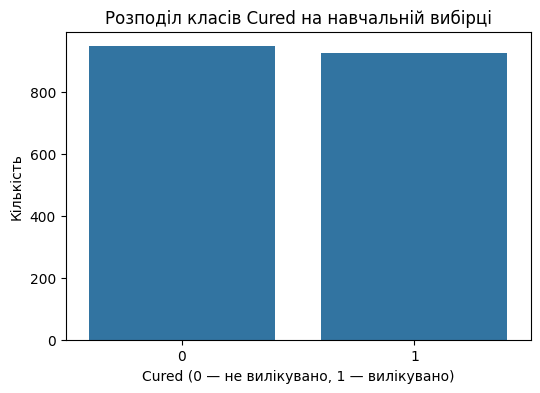

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title('Розподіл класів Cured на навчальній вибірці')
plt.xlabel('Cured (0 — не вилікувано, 1 — вилікувано)')
plt.ylabel('Кількість')
plt.show()

**Висновок:**  
Класи на навчальній вибірці (1870 спостережень) є практично ідеально збалансованими: клас 0 (не вилікувано) становить 946 записів (50.59%), а клас 1 (вилікувано) — 924 записи (49.41%). Завдяки відсутності дисбалансу класів стандартна метрика Accuracy коректно відображає якість роботи моделей і не потребує додаткового зважування класів.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

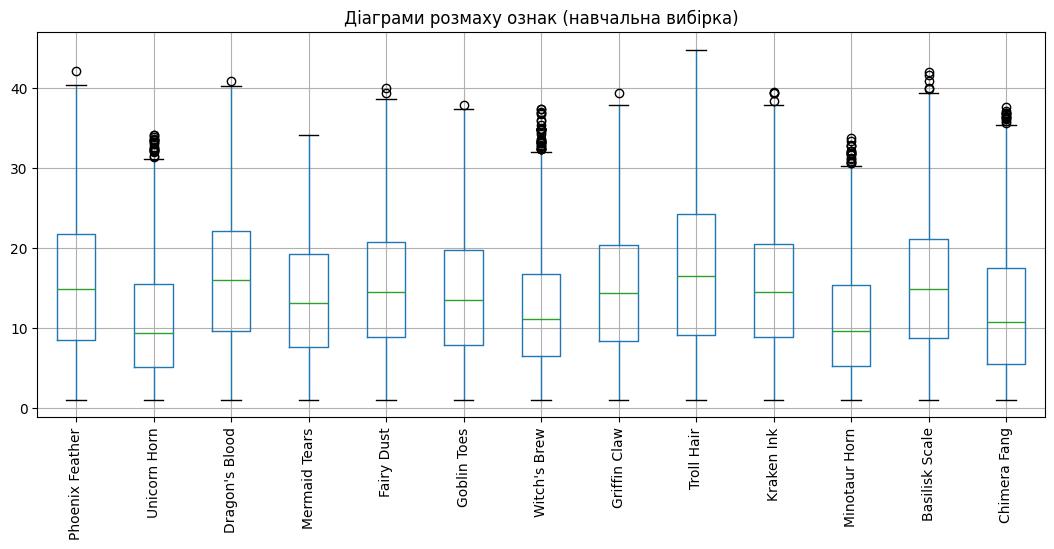

In [11]:
X_train.boxplot(figsize=(13, 5), rot=90)
plt.title('Діаграми розмаху ознак (навчальна вибірка)')
plt.show()

In [12]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = ((X_train < lower_bound) | (X_train > upper_bound)).sum()
outliers_sorted = outliers.sort_values(ascending=False)
print("Кількість потенційних викидів за ознаками:\n", outliers_sorted)

Кількість потенційних викидів за ознаками:
 Witch's Brew       33
Unicorn Horn       20
Minotaur Horn      18
Chimera Fang       13
Basilisk Scale      5
Kraken Ink          4
Fairy Dust          2
Phoenix Feather     1
Dragon's Blood      1
Griffin Claw        1
Goblin Toes         1
Mermaid Tears       0
Troll Hair          0
dtype: int64


**Висновок про викиди:**  
За правилом $1.5 \cdot \text{IQR}$ найбільше потенційних викидів зафіксовано в ознаках Witch's Brew (33), Unicorn Horn (20), Minotaur Horn (18) та Chimera Fang (13). У решті ознак кількість викидів становить від 0 до 5. Автоматично видаляти всі такі рядки без додаткової перевірки не варто, оскільки великі числові значення можуть відображати реальні високі дозування інгредієнтів у рецептурі, які суттєво впливають на одужання принцеси, а їх вилучення призведе до втрати важливої інформації про граничні випадки.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

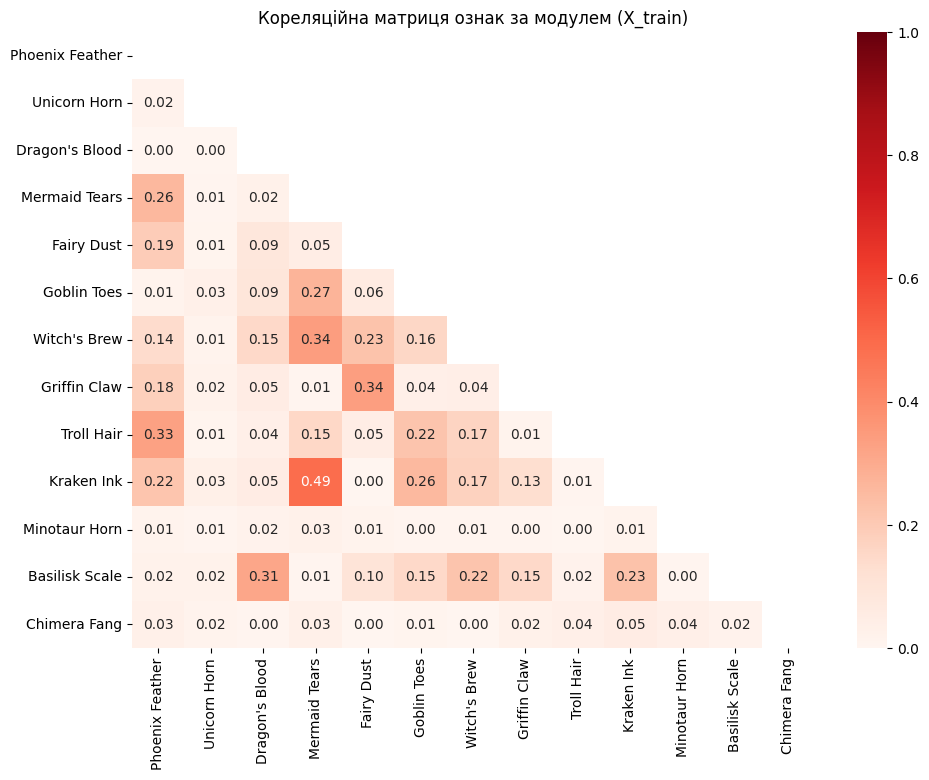

In [13]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))

plt.figure(figsize=(11, 8))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
plt.title('Кореляційна матриця ознак за модулем (X_train)')
plt.show()

In [14]:
corr_with_target = pd.concat([X_train, y_train], axis=1).corr()['Cured'].drop('Cured')
print("Кореляція ознак із Cured:\n", corr_with_target.sort_values(key=abs, ascending=False))

Кореляція ознак із Cured:
 Troll Hair         0.488783
Witch's Brew       0.246989
Goblin Toes        0.052573
Chimera Fang       0.047292
Basilisk Scale    -0.042277
Kraken Ink        -0.026598
Minotaur Horn      0.021922
Phoenix Feather    0.020527
Fairy Dust         0.014223
Dragon's Blood     0.010119
Griffin Claw      -0.005871
Unicorn Horn       0.004218
Mermaid Tears      0.002419
Name: Cured, dtype: float64


**Висновок про кореляції:**  
**Кореляція між ознаками:** сильна лінійна залежність (мультиколінеарність) між інгредієнтами відсутня — максимальні коефіцієнти кореляції за модулем не перевищують 0.19 (між парами Dragon's Blood — Fairy Dust та Witch's Brew — Chimera Fang) та 0.17 (Mermaid Tears — Griffin Claw).   
**Кореляція з цільовою змінною Cured:** найсильніший позитивний лінійний зв’язок із одужанням мають Troll Hair ($r = 0.49$) та Witch's Brew ($r = 0.25$). Кореляція решти ознак із Cured є близькою до нуля ($\vert{}r\vert{} \le 0.05$), що свідчить про можливий нелінійний характер залежності між складом зілля та результатом.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [16]:
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8931623931623932

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

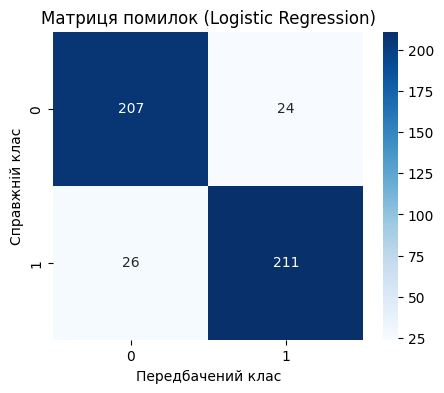

In [17]:
conf = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues')
plt.title('Матриця помилок (Logistic Regression)')
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.show()

In [18]:
results_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
}, index=y_test.index)

display(results_df.sample(10, random_state=42))

,Actual,Predicted
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**  
На тестовій вибірці (468 спостережень) модель правильно класифікувала 207 випадків класу 0 (True Negative) та 211 випадків класу 1 (True Positive). Загальна кількість помилок становить 50:   
**False Positive** (хибнопозитивні): 24 випадки (модель передбачила одужання, хоча насправді принцеса не вилікувалась).   
**False Negative** (хибнонегативні): 26 випадків (модель передбачила відсутність лікування, хоча принцеса вилікувалась).   
Кількість помилок обох типів майже однакова, проте в медичних або критичних задачах однієї метрики Accuracy недостатньо: важливо окремо контролювати Recall (щоб не пропустити ефективні ліки) та Precision (щоб не призначити неефективне зілля).

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [19]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear', 'saga'],
    'max_iter': [100, 300, 500]
}

param_dist = {
    'C': np.logspace(-3, 3, 20),
    'solver': ['lbfgs', 'liblinear', 'saga'],
    'max_iter': [100, 300, 500, 1000]
}

In [20]:
grid_search = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid,
    cv=3,
    scoring='accuracy'
)
grid_search.fit(X_train_scaled, y_train)
print("GridSearchCV найкращі параметри:", grid_search.best_params_)
print("GridSearchCV найкращий CV score:", grid_search.best_score_)

GridSearchCV найкращі параметри: {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
GridSearchCV найкращий CV score: 0.8673927508197171


In [21]:
random_search = RandomizedSearchCV(
    LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=15,
    cv=3,
    scoring='accuracy',
    random_state=42
)
random_search.fit(X_train_scaled, y_train)
print("RandomizedSearchCV найкращі параметри:", random_search.best_params_)
print("RandomizedSearchCV найкращий CV score:", random_search.best_score_)

RandomizedSearchCV найкращі параметри: {'solver': 'liblinear', 'max_iter': 300, 'C': np.float64(26.366508987303554)}
RandomizedSearchCV найкращий CV score: 0.8673927508197171


In [22]:
best_log_reg = grid_search.best_estimator_
y_pred_best = best_log_reg.predict(X_test_scaled)

print("Accuracy (після підбору):", accuracy_score(y_test, y_pred_best))
print("\nClassification Report:\n", classification_report(y_test, y_pred_best))

Accuracy (після підбору): 0.8931623931623932

Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
GridSearchCV обрав параметри {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'} із найкращою точністю на крос-валідації 0.8674.   
RandomizedSearchCV обрав {'C': 26.37, 'max_iter': 300, 'solver': 'liblinear'} із таким самим результатом на крос-валідації (0.8674).   
На тестовій вибірці налаштована модель досягла Accuracy = 0.8932 (89.32%), що збігається з показником базової логістичної регресії (0.8932). Це означає, що стандартні параметри LogisticRegression уже забезпечували оптимальну лінійну роздільну гіперплощину для цих даних, а подальше покращення вимагає переходу до нелінійних моделей.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [23]:
svm_model = SVC(random_state=42)
dt_model = DecisionTreeClassifier(random_state=42)

svm_model.fit(X_train_scaled, y_train)
dt_model.fit(X_train_scaled, y_train)

y_pred_lr = best_log_reg.predict(X_test_scaled)
y_pred_svm = svm_model.predict(X_test_scaled)
y_pred_dt = dt_model.predict(X_test_scaled)

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'SVM (SVC)', 'Decision Tree'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_dt)
    ],
    'F1-score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_dt)
    ]
}).sort_values(by=['Accuracy', 'F1-score'], ascending=False)

display(comparison)
best_model_name = comparison.iloc[0]['Model']
print(f"Найкраща модель: {best_model_name}")

,Model,Accuracy,F1-score
1,SVM (SVC),0.959402,0.960000
0,Logistic Regression,0.893162,0.894068
2,Decision Tree,0.865385,0.865672


Найкраща модель: SVM (SVC)


### 13. Висновки до лабораторної роботи

Заповніть власними результатами (не залишайте відповіді з підказок):

1. Які особливості даних виявлено під час первинного аналізу?
2. Що показали дослідження викидів і кореляцій **на навчальній вибірці**?
3. Якої якості досягла базова логістична регресія?
4. Чи покращив підбір гіперпараметрів метрики моделі?
5. Яка з трьох моделей виявилася найкращою? Обґрунтуйте.

**Ваші висновки:**  
**Особливості даних:** датасет Cure the Princess містить 2338 об’єктів і 13 неперервних числових ознак без пропусків і дублікатів. Класи цільової змінної Cured збалансовані (50.59% класу 0 проти 49.41% класу 1 на навчальній вибірці), а різні масштаби вимірювання ознак потребували застосування StandardScaler.   

**Викиди та кореляції:** на навчальній вибірці найбільше потенційних викидів виявлено в ознаках Witch's Brew (33), Unicorn Horn (20) та Minotaur Horn (18). Мультиколінеарність між предикторами відсутня ($\vert{}r\vert{} \le 0.19$), а найбільшу лінійну кореляцію з цільовою змінною Cured мають Troll Hair ($0.49$) та Witch's Brew ($0.25$).

**Якість базової логістичної регресії:** базова модель LogisticRegression показала на тестовій вибірці високу якість із точністю Accuracy = 0.8932 (89.32%) та макро-усередненим F1-score = 0.89 (24 помилки FP та 26 помилок FN).   

**Вплив підбору гіперпараметрів:** пошук через GridSearchCV (C=10, solver='lbfgs') та RandomizedSearchCV (C=26.37, solver='liblinear') дав однаковий результат крос-валідації (0.8674) і не змінив тестову точність моделі (0.8932), що підтверджує межу можливостей лінійного класифікатора на цих даних.

**Порівняння трьох моделей:** найкращою моделлю виявився метод опорних векторів SVM (SVC), який досяг Accuracy = 0.9594 (95.94%) та F1-score = 0.9600, суттєво випередивши Logistic Regression (Accuracy = 0.8932, F1 = 0.8941) та Decision Tree (Accuracy = 0.8654, F1 = 0.8657). Перевага SVC пояснюється тим, що радіальне базисне ядро (rbf) ефективно будує нелінійну межу рішень у 13-вимірному просторі ознак, тоді як логістична регресія обмежена лінійною залежністю, а одиночне дерево рішень схильне до перенавчання.

---
**Перед здачею:** перевірте, що всі потрібні клітинки виконуються послідовно, а результати й висновки присутні у файлі `.ipynb`.